## Project 1: Customer Churn Analysis Dashboard

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 📌 Goal: Analyze a dataset of customers, identify churn trends, and visualize key insights.

Tools Used:
    1. Pandas → data manipulation & cleaning
    2. Matplotlib / Seaborn → churn trend plots, heatmaps, bar charts
    3. Python concepts → loops, conditionals, functions, file handling

✅ Industry Fit: This simulates real-world data analytics + visualization jobs in customer-focused companies.

### What is Churn Analysis?
--> Customer churn analysis is the process of using your churn data to understand:

1. Which customers are leaving?
2. Why are they leaving?
3. Which customers are likely to churn shortly?
4. What can you do to reduce churn?

https://www.chargebee.com/blog/churn-analysis/

Customer churn analysis is the process of evaluating a business's customer attrition rate to understand why customers stop using a product or service and how to prevent them from leaving. By analyzing customer data, businesses can identify the patterns and factors leading to churn, such as drops in engagement or satisfaction, and then implement strategies to improve customer retention and loyalty

In [2]:
data = pd.read_csv("customer_churn_dataset.csv")

In [3]:
data

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,CUST1000,Customer_0,56,Female,North,Standard,504.57,3,3,21.9,Debit Card,Month-to-Month,Yes,No
1,CUST1001,Customer_1,69,Male,South,Premium,537.55,37,3,29.0,Wallet,Month-to-Month,No,No
2,CUST1002,Customer_2,46,Female,South,Basic,218.99,37,5,9.1,Net Banking,Month-to-Month,Yes,No
3,CUST1003,Customer_3,32,Other,East,Standard,364.57,3,0,7.2,Wallet,Month-to-Month,Yes,No
4,CUST1004,Customer_4,60,Male,North,Basic,1202.31,63,1,26.4,Debit Card,Month-to-Month,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,CUST2995,Customer_1995,63,Female,South,Basic,790.53,24,1,26.0,UPI,Two Year,Yes,Yes
1996,CUST2996,Customer_1996,67,Female,South,Basic,1388.70,36,3,1.0,Net Banking,One Year,Yes,Yes
1997,CUST2997,Customer_1997,69,Female,East,Standard,1514.74,34,2,39.2,UPI,Month-to-Month,Yes,No
1998,CUST2998,Customer_1998,24,Male,West,Standard,1015.87,54,2,16.9,Credit Card,One Year,No,No


In [4]:
data.head(2)

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,CUST1000,Customer_0,56,Female,North,Standard,504.57,3,3,21.9,Debit Card,Month-to-Month,Yes,No
1,CUST1001,Customer_1,69,Male,South,Premium,537.55,37,3,29.0,Wallet,Month-to-Month,No,No


In [5]:
data.shape

(2000, 14)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerID            2000 non-null   object 
 1   Name                  2000 non-null   object 
 2   Age                   2000 non-null   int64  
 3   Gender                2000 non-null   object 
 4   Region                2000 non-null   object 
 5   SubscriptionPlan      2000 non-null   object 
 6   MonthlyCharges        2000 non-null   float64
 7   TenureMonths          2000 non-null   int64  
 8   SupportTicketsRaised  2000 non-null   int64  
 9   UsageHoursPerWeek     2000 non-null   float64
 10  PaymentMethod         2000 non-null   object 
 11  ContractType          2000 non-null   object 
 12  AutoRenewal           2000 non-null   object 
 13  Churn                 2000 non-null   object 
dtypes: float64(2), int64(3), object(9)
memory usage: 218.9+ KB


#### Calculate churn rate and visualize trends:

1. Churn by age group, subscription plan, region, or usage.
2. Monthly churn rate trend with line charts.

### Churn by Age

#### Can be done with the help of Filtering process, value_counts(), groupby()

#### 1. Filtering

In [7]:
# below is filtering but answer will be in boolean format
data["Churn"] == "Yes"

0       False
1       False
2       False
3       False
4       False
        ...  
1995     True
1996     True
1997    False
1998    False
1999    False
Name: Churn, Length: 2000, dtype: bool

In [8]:
# To get the answer int the readable format in filtering
data[data["Churn"] == "Yes"]

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
9,CUST1009,Customer_9,40,Male,West,Basic,899.54,36,1,27.7,Wallet,Month-to-Month,Yes,Yes
11,CUST1011,Customer_11,28,Male,North,Basic,1851.68,64,2,6.8,Debit Card,Month-to-Month,Yes,Yes
12,CUST1012,Customer_12,41,Male,West,Basic,1411.60,26,4,17.5,Net Banking,Two Year,Yes,Yes
13,CUST1013,Customer_13,53,Female,North,Premium,1983.35,48,1,38.6,UPI,One Year,No,Yes
14,CUST1014,Customer_14,57,Male,North,Premium,1789.08,40,3,17.0,Debit Card,Two Year,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1990,CUST2990,Customer_1990,34,Male,West,Basic,655.86,4,2,15.2,UPI,Month-to-Month,Yes,Yes
1993,CUST2993,Customer_1993,32,Other,North,Basic,288.47,55,1,4.1,Debit Card,Month-to-Month,Yes,Yes
1994,CUST2994,Customer_1994,44,Male,East,Standard,209.57,20,5,23.7,Credit Card,One Year,Yes,Yes
1995,CUST2995,Customer_1995,63,Female,South,Basic,790.53,24,1,26.0,UPI,Two Year,Yes,Yes


In [9]:
# Making the new dataframe from the previous dataframe in which the customer churn out.
churned_data = data[data["Churn"] == "Yes"]

In [10]:
churned_data

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
9,CUST1009,Customer_9,40,Male,West,Basic,899.54,36,1,27.7,Wallet,Month-to-Month,Yes,Yes
11,CUST1011,Customer_11,28,Male,North,Basic,1851.68,64,2,6.8,Debit Card,Month-to-Month,Yes,Yes
12,CUST1012,Customer_12,41,Male,West,Basic,1411.60,26,4,17.5,Net Banking,Two Year,Yes,Yes
13,CUST1013,Customer_13,53,Female,North,Premium,1983.35,48,1,38.6,UPI,One Year,No,Yes
14,CUST1014,Customer_14,57,Male,North,Premium,1789.08,40,3,17.0,Debit Card,Two Year,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1990,CUST2990,Customer_1990,34,Male,West,Basic,655.86,4,2,15.2,UPI,Month-to-Month,Yes,Yes
1993,CUST2993,Customer_1993,32,Other,North,Basic,288.47,55,1,4.1,Debit Card,Month-to-Month,Yes,Yes
1994,CUST2994,Customer_1994,44,Male,East,Standard,209.57,20,5,23.7,Credit Card,One Year,Yes,Yes
1995,CUST2995,Customer_1995,63,Female,South,Basic,790.53,24,1,26.0,UPI,Two Year,Yes,Yes


In [11]:
AgeSeries_Data = churned_data["Age"]

In [12]:
AgeSeries_Data

9       40
11      28
12      41
13      53
14      57
        ..
1990    34
1993    32
1994    44
1995    63
1996    67
Name: Age, Length: 598, dtype: int64

In [13]:
# how many people are there - i want to know there age group
data["Age"].unique()

array([56, 69, 46, 32, 60, 25, 38, 36, 40, 28, 41, 53, 57, 20, 39, 19, 61,
       47, 55, 50, 29, 42, 66, 44, 59, 45, 33, 64, 68, 54, 24, 26, 35, 21,
       31, 67, 43, 37, 52, 34, 23, 51, 27, 48, 65, 62, 58, 18, 22, 30, 49,
       63])

In [14]:
# Now i want to know the age group that are churned out
churned_data["Age"].unique()

array([40, 28, 41, 53, 57, 55, 19, 50, 39, 61, 42, 44, 59, 24, 26, 45, 52,
       43, 51, 65, 64, 32, 18, 25, 56, 54, 30, 21, 46, 49, 62, 37, 69, 20,
       23, 68, 66, 22, 48, 58, 36, 63, 34, 29, 47, 67, 33, 38, 60, 31, 27,
       35])

In [15]:
churned_data[churned_data["Age"] == 40]

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
9,CUST1009,Customer_9,40,Male,West,Basic,899.54,36,1,27.7,Wallet,Month-to-Month,Yes,Yes
231,CUST1231,Customer_231,40,Female,West,Standard,1319.62,8,1,11.5,Wallet,Two Year,Yes,Yes
283,CUST1283,Customer_283,40,Female,North,Basic,847.04,50,2,6.9,Wallet,Two Year,Yes,Yes
759,CUST1759,Customer_759,40,Male,South,Premium,896.93,60,3,12.1,Wallet,Month-to-Month,Yes,Yes
993,CUST1993,Customer_993,40,Female,South,Standard,1556.62,62,2,5.7,Credit Card,Two Year,No,Yes
1112,CUST2112,Customer_1112,40,Female,North,Basic,1490.09,60,2,22.7,UPI,Two Year,No,Yes
1175,CUST2175,Customer_1175,40,Male,East,Basic,998.94,22,2,17.9,Credit Card,One Year,No,Yes
1289,CUST2289,Customer_1289,40,Male,South,Basic,1086.24,54,4,16.1,Debit Card,One Year,Yes,Yes
1297,CUST2297,Customer_1297,40,Female,West,Basic,952.23,3,1,29.5,Debit Card,One Year,Yes,Yes
1396,CUST2396,Customer_1396,40,Male,South,Premium,283.27,39,1,14.0,Debit Card,Month-to-Month,Yes,Yes


In [16]:
churned_data[churned_data["Age"] == 40].shape

(15, 14)

In [17]:
temp = data.sort_values(by="Age")

In [18]:
temp["Age"].unique()

array([18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69])

In [19]:
temp["Age"].unique()[(len(temp["Age"].unique()))-1]

np.int64(69)

### collecting data for making the plot on the basis of the age for churn rate

In [20]:
# DataFrame.sort_values(by, *, axis=0, ascending=True, inplace=False, kind='quicksort', na_position='last', ignore_index=False, key=None)
T40APs = data[data["Age"] == 40]

In [21]:
T40APs.reset_index()

,index,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,9,CUST1009,Customer_9,40,Male,West,Basic,899.54,36,1,27.7,Wallet,Month-to-Month,Yes,Yes
1,86,CUST1086,Customer_86,40,Female,West,Basic,895.46,9,3,35.8,Net Banking,Month-to-Month,No,No
2,129,CUST1129,Customer_129,40,Male,West,Premium,1146.39,4,3,1.6,Wallet,Two Year,Yes,No
3,165,CUST1165,Customer_165,40,Female,North,Standard,574.90,69,2,29.7,Debit Card,One Year,Yes,No
4,231,CUST1231,Customer_231,40,Female,West,Standard,1319.62,8,1,11.5,Wallet,Two Year,Yes,Yes
5,283,CUST1283,Customer_283,40,Female,North,Basic,847.04,50,2,6.9,Wallet,Two Year,Yes,Yes
6,393,CUST1393,Customer_393,40,Female,East,Premium,932.74,53,2,5.8,Wallet,Month-to-Month,Yes,No
7,408,CUST1408,Customer_408,40,Male,West,Basic,972.05,2,3,23.5,Credit Card,One Year,Yes,No
8,440,CUST1440,Customer_440,40,Male,South,Standard,921.59,57,2,36.9,Wallet,Month-to-Month,Yes,No
9,446,CUST1446,Customer_446,40,Female,South,Standard,947.47,12,1,7.4,Credit Card,Month-to-Month,No,No


In [22]:
data[data["Age"] == 40].reset_index()

,index,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,9,CUST1009,Customer_9,40,Male,West,Basic,899.54,36,1,27.7,Wallet,Month-to-Month,Yes,Yes
1,86,CUST1086,Customer_86,40,Female,West,Basic,895.46,9,3,35.8,Net Banking,Month-to-Month,No,No
2,129,CUST1129,Customer_129,40,Male,West,Premium,1146.39,4,3,1.6,Wallet,Two Year,Yes,No
3,165,CUST1165,Customer_165,40,Female,North,Standard,574.90,69,2,29.7,Debit Card,One Year,Yes,No
4,231,CUST1231,Customer_231,40,Female,West,Standard,1319.62,8,1,11.5,Wallet,Two Year,Yes,Yes
5,283,CUST1283,Customer_283,40,Female,North,Basic,847.04,50,2,6.9,Wallet,Two Year,Yes,Yes
6,393,CUST1393,Customer_393,40,Female,East,Premium,932.74,53,2,5.8,Wallet,Month-to-Month,Yes,No
7,408,CUST1408,Customer_408,40,Male,West,Basic,972.05,2,3,23.5,Credit Card,One Year,Yes,No
8,440,CUST1440,Customer_440,40,Male,South,Standard,921.59,57,2,36.9,Wallet,Month-to-Month,Yes,No
9,446,CUST1446,Customer_446,40,Female,South,Standard,947.47,12,1,7.4,Credit Card,Month-to-Month,No,No


In [23]:
C40APs = churned_data[churned_data["Age"] == 40]

In [24]:
C40APs.reset_index(inplace=True)

##### new idea - i will create a dictionary of age : no of peoples,  . instead of creating a seperate dataframes for each ages, that will be very much, inspite of that lert create a dictinary that will be easy

In [25]:
total_peoples = {
    't18' : data[data["Age"] == 18].reset_index(),
    't19' : data[data["Age"] == 19].reset_index(),
    't20' : data[data["Age"] == 20].reset_index(),
    't21' : data[data["Age"] == 21].reset_index(),
    't22' : data[data["Age"] == 22].reset_index(),
    't23' : data[data["Age"] == 23].reset_index(),
    't24' : data[data["Age"] == 24].reset_index(),
    't25' : data[data["Age"] == 25].reset_index(),
    't26' : data[data["Age"] == 26].reset_index(),
    't27' : data[data["Age"] == 27].reset_index(),
    't28' : data[data["Age"] == 28].reset_index(),
    't29' : data[data["Age"] == 29].reset_index(),
    't30' : data[data["Age"] == 30].reset_index(),
    't31' : data[data["Age"] == 31].reset_index(),
    't32' : data[data["Age"] == 32].reset_index(),
    't33' : data[data["Age"] == 33].reset_index(),
    't34' : data[data["Age"] == 34].reset_index(),
    't35' : data[data["Age"] == 35].reset_index(),
    't36' : data[data["Age"] == 36].reset_index(),
    't37' : data[data["Age"] == 37].reset_index(),
    't38' : data[data["Age"] == 38].reset_index(),
    't39' : data[data["Age"] == 39].reset_index(),
    't40' : data[data["Age"] == 40].reset_index(),
    't41' : data[data["Age"] == 41].reset_index(),
    't42' : data[data["Age"] == 42].reset_index(),
    't43' : data[data["Age"] == 43].reset_index(),
    't44' : data[data["Age"] == 44].reset_index(),
    't45' : data[data["Age"] == 45].reset_index(),
    't46' : data[data["Age"] == 46].reset_index(),
    't47' : data[data["Age"] == 47].reset_index(),
    't48' : data[data["Age"] == 48].reset_index(),
    't49' : data[data["Age"] == 49].reset_index(),
    't50' : data[data["Age"] == 50].reset_index(),
    't51' : data[data["Age"] == 51].reset_index(),
    't52' : data[data["Age"] == 52].reset_index(),
    't53' : data[data["Age"] == 53].reset_index(),
    't54' : data[data["Age"] == 54].reset_index(),
    't55' : data[data["Age"] == 55].reset_index(),
    't56' : data[data["Age"] == 56].reset_index(),
    't57' : data[data["Age"] == 57].reset_index(),
    't58' : data[data["Age"] == 58].reset_index(),
    't59' : data[data["Age"] == 59].reset_index(),
    't60' : data[data["Age"] == 60].reset_index(),
    't61' : data[data["Age"] == 61].reset_index(),
    't62' : data[data["Age"] == 62].reset_index(),
    't63' : data[data["Age"] == 63].reset_index(),
    't64' : data[data["Age"] == 64].reset_index(),
    't65' : data[data["Age"] == 65].reset_index(),
    't66' : data[data["Age"] == 66].reset_index(),
    't67' : data[data["Age"] == 67].reset_index(),
    't68' : data[data["Age"] == 68].reset_index(),
    't69' : data[data["Age"] == 69].reset_index()
}

In [26]:
total_peoples['t18']

,index,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,101,CUST1101,Customer_101,18,Female,North,Basic,945.44,57,1,19.4,Wallet,Two Year,No,Yes
1,106,CUST1106,Customer_106,18,Female,North,Basic,218.21,31,3,14.0,Debit Card,Month-to-Month,Yes,No
2,138,CUST1138,Customer_138,18,Female,South,Premium,1805.71,57,4,17.1,Credit Card,One Year,Yes,No
3,144,CUST1144,Customer_144,18,Male,East,Premium,968.22,39,0,14.5,Wallet,Month-to-Month,Yes,No
4,193,CUST1193,Customer_193,18,Female,South,Basic,1773.50,58,3,38.1,Debit Card,Month-to-Month,Yes,No
5,235,CUST1235,Customer_235,18,Male,East,Standard,1333.77,14,2,2.3,Credit Card,Month-to-Month,No,Yes
6,278,CUST1278,Customer_278,18,Male,North,Standard,1417.08,17,2,34.9,UPI,Month-to-Month,No,No
7,295,CUST1295,Customer_295,18,Male,West,Premium,1947.00,69,1,20.5,UPI,Month-to-Month,Yes,Yes
8,433,CUST1433,Customer_433,18,Male,West,Premium,278.18,67,2,8.5,Net Banking,Month-to-Month,No,Yes
9,490,CUST1490,Customer_490,18,Male,North,Basic,1475.84,11,0,23.3,Wallet,One Year,Yes,No


In [27]:
x = total_peoples['t18'].shape

In [28]:
x

(40, 15)

In [29]:
# size of the data (no of peoples)
x[0]

40

In [30]:
churned_peoples = {
    'c18' : churned_data[churned_data["Age"] == 18].reset_index(),
    'c19' : churned_data[churned_data["Age"] == 19].reset_index(),
    'c20' : churned_data[churned_data["Age"] == 20].reset_index(),
    'c21' : churned_data[churned_data["Age"] == 21].reset_index(),
    'c22' : churned_data[churned_data["Age"] == 22].reset_index(),
    'c23' : churned_data[churned_data["Age"] == 23].reset_index(),
    'c24' : churned_data[churned_data["Age"] == 24].reset_index(),
    'c25' : churned_data[churned_data["Age"] == 25].reset_index(),
    'c26' : churned_data[churned_data["Age"] == 26].reset_index(),
    'c27' : churned_data[churned_data["Age"] == 27].reset_index(),
    'c28' : churned_data[churned_data["Age"] == 28].reset_index(),
    'c29' : churned_data[churned_data["Age"] == 29].reset_index(),
    'c30' : churned_data[churned_data["Age"] == 30].reset_index(),
    'c31' : churned_data[churned_data["Age"] == 31].reset_index(),
    'c32' : churned_data[churned_data["Age"] == 12].reset_index(),
    'c33' : churned_data[churned_data["Age"] == 33].reset_index(),
    'c34' : churned_data[churned_data["Age"] == 34].reset_index(),
    'c35' : churned_data[churned_data["Age"] == 35].reset_index(),
    'c36' : churned_data[churned_data["Age"] == 36].reset_index(),
    'c37' : churned_data[churned_data["Age"] == 37].reset_index(),
    'c38' : churned_data[churned_data["Age"] == 38].reset_index(),
    'c39' : churned_data[churned_data["Age"] == 39].reset_index(),
    'c40' : churned_data[churned_data["Age"] == 40].reset_index(),
    'c41' : churned_data[churned_data["Age"] == 41].reset_index(),
    'c42' : churned_data[churned_data["Age"] == 42].reset_index(),
    'c43' : churned_data[churned_data["Age"] == 43].reset_index(),
    'c44' : churned_data[churned_data["Age"] == 44].reset_index(),
    'c45' : churned_data[churned_data["Age"] == 45].reset_index(),
    'c46' : churned_data[churned_data["Age"] == 46].reset_index(),
    'c47' : churned_data[churned_data["Age"] == 47].reset_index(),
    'c48' : churned_data[churned_data["Age"] == 48].reset_index(),
    'c49' : churned_data[churned_data["Age"] == 49].reset_index(),
    'c50' : churned_data[churned_data["Age"] == 50].reset_index(),
    'c51' : churned_data[churned_data["Age"] == 51].reset_index(),
    'c52' : churned_data[churned_data["Age"] == 52].reset_index(),
    'c53' : churned_data[churned_data["Age"] == 53].reset_index(),
    'c54' : churned_data[churned_data["Age"] == 54].reset_index(),
    'c55' : churned_data[churned_data["Age"] == 55].reset_index(),
    'c56' : churned_data[churned_data["Age"] == 56].reset_index(),
    'c57' : churned_data[churned_data["Age"] == 57].reset_index(),
    'c58' : churned_data[churned_data["Age"] == 58].reset_index(),
    'c59' : churned_data[churned_data["Age"] == 59].reset_index(),
    'c60' : churned_data[churned_data["Age"] == 60].reset_index(),
    'c61' : churned_data[churned_data["Age"] == 61].reset_index(),
    'c62' : churned_data[churned_data["Age"] == 62].reset_index(),
    'c63' : churned_data[churned_data["Age"] == 63].reset_index(),
    'c64' : churned_data[churned_data["Age"] == 64].reset_index(),
    'c65' : churned_data[churned_data["Age"] == 65].reset_index(),
    'c66' : churned_data[churned_data["Age"] == 66].reset_index(),
    'c67' : churned_data[churned_data["Age"] == 67].reset_index(),
    'c68' : churned_data[churned_data["Age"] == 68].reset_index(),
    'c69' : churned_data[churned_data["Age"] == 69].reset_index()
}

##### filtering --> 
1. churned_data['Age'] == 51  --> will give the boolean output
2. to get the desired output in the form of the dataFrame (human Readable)
3.  churned_data[churned_data["Age"] == 51]

In [31]:
# i want to know the no of peoples in the data and in the churned data of the same age 
total_peoples['t25'].shape[0]

40

In [32]:
churned_peoples['c25'].shape[0]

11

In [33]:
# formula
i = 25
percentage = ((churned_peoples[f'c{i}'].shape[0])/(total_peoples[f't{i}'].shape[0]))*100

In [34]:
percentage

27.500000000000004

##### preparing to make plot

In [35]:
# x axis is the age
ages = data["Age"].sort_values().unique()
x = [x for x in ages]

In [36]:
data["Age"].sort_values().unique()[len(data["Age"].sort_values().unique())-1]

np.int64(69)

In [37]:
length = len(data["Age"].sort_values().unique())

In [38]:
length

52

In [39]:
# y axis is the percentage of people churned
y = []
for i in range(data["Age"].sort_values().unique()[0], data["Age"].sort_values().unique()[(len(data["Age"].sort_values().unique())) - 1] + 1):
    percentage = ((churned_peoples[f'c{i}'].shape[0])/(total_peoples[f't{i}'].shape[0]))*100
    y.append(percentage)

In [40]:
len(y)

52

In [41]:
x

[np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27),
 np.int64(28),
 np.int64(29),
 np.int64(30),
 np.int64(31),
 np.int64(32),
 np.int64(33),
 np.int64(34),
 np.int64(35),
 np.int64(36),
 np.int64(37),
 np.int64(38),
 np.int64(39),
 np.int64(40),
 np.int64(41),
 np.int64(42),
 np.int64(43),
 np.int64(44),
 np.int64(45),
 np.int64(46),
 np.int64(47),
 np.int64(48),
 np.int64(49),
 np.int64(50),
 np.int64(51),
 np.int64(52),
 np.int64(53),
 np.int64(54),
 np.int64(55),
 np.int64(56),
 np.int64(57),
 np.int64(58),
 np.int64(59),
 np.int64(60),
 np.int64(61),
 np.int64(62),
 np.int64(63),
 np.int64(64),
 np.int64(65),
 np.int64(66),
 np.int64(67),
 np.int64(68),
 np.int64(69)]

In [42]:
y

[32.5,
 23.076923076923077,
 27.500000000000004,
 32.35294117647059,
 30.952380952380953,
 29.72972972972973,
 29.03225806451613,
 27.500000000000004,
 33.33333333333333,
 26.47058823529412,
 27.027027027027028,
 35.8974358974359,
 41.17647058823529,
 22.22222222222222,
 0.0,
 16.129032258064516,
 31.11111111111111,
 17.647058823529413,
 28.125,
 19.35483870967742,
 15.625,
 43.24324324324324,
 34.883720930232556,
 35.714285714285715,
 34.78260869565217,
 20.754716981132077,
 32.25806451612903,
 38.095238095238095,
 30.612244897959183,
 28.205128205128204,
 25.0,
 29.545454545454547,
 34.04255319148936,
 33.33333333333333,
 28.57142857142857,
 28.947368421052634,
 26.53061224489796,
 29.03225806451613,
 24.390243902439025,
 37.2093023255814,
 23.333333333333332,
 38.70967741935484,
 31.03448275862069,
 31.57894736842105,
 47.72727272727273,
 24.137931034482758,
 24.489795918367346,
 45.16129032258064,
 26.53061224489796,
 32.25806451612903,
 33.33333333333333,
 21.62162162162162]

In [43]:
y

[32.5,
 23.076923076923077,
 27.500000000000004,
 32.35294117647059,
 30.952380952380953,
 29.72972972972973,
 29.03225806451613,
 27.500000000000004,
 33.33333333333333,
 26.47058823529412,
 27.027027027027028,
 35.8974358974359,
 41.17647058823529,
 22.22222222222222,
 0.0,
 16.129032258064516,
 31.11111111111111,
 17.647058823529413,
 28.125,
 19.35483870967742,
 15.625,
 43.24324324324324,
 34.883720930232556,
 35.714285714285715,
 34.78260869565217,
 20.754716981132077,
 32.25806451612903,
 38.095238095238095,
 30.612244897959183,
 28.205128205128204,
 25.0,
 29.545454545454547,
 34.04255319148936,
 33.33333333333333,
 28.57142857142857,
 28.947368421052634,
 26.53061224489796,
 29.03225806451613,
 24.390243902439025,
 37.2093023255814,
 23.333333333333332,
 38.70967741935484,
 31.03448275862069,
 31.57894736842105,
 47.72727272727273,
 24.137931034482758,
 24.489795918367346,
 45.16129032258064,
 26.53061224489796,
 32.25806451612903,
 33.33333333333333,
 21.62162162162162]

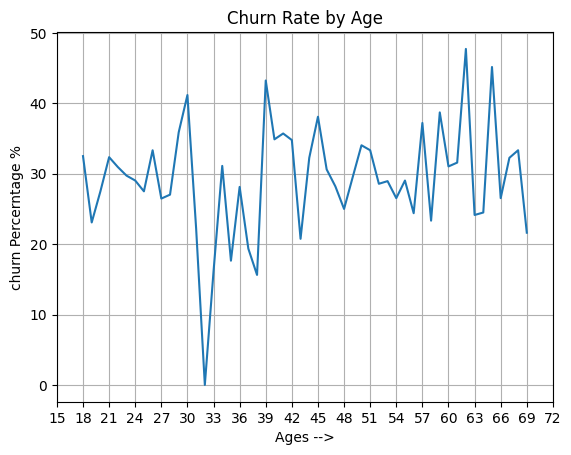

<Figure size 3000x1000 with 0 Axes>

In [60]:
plt.plot(x,y)
plt.grid(True)
plt.title("Churn Rate by Age")
plt.xlabel("Ages -->")
plt.ylabel("churn Percerntage %")
plt.xticks(np.arange(15, 75, 3))
# Create a figure with a wider width (e.g., 12 inches) and standard height (e.g., 6 inches)
plt.figure(figsize=(30, 10))
plt.show()

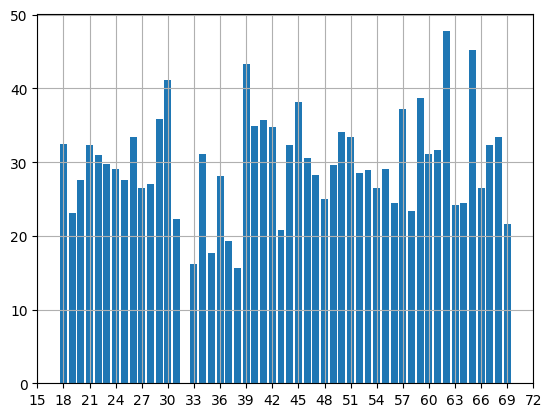

<Figure size 3000x1000 with 0 Axes>

In [61]:
plt.bar(x,y)
plt.grid(True)
plt.xticks(np.arange(15, 75, 3))
# Create a figure with a wider width (e.g., 12 inches) and standard height (e.g., 6 inches)
plt.figure(figsize=(30, 10))
plt.show()

### Churn by Subscription Plan

In [62]:
data.head(8)

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,CUST1000,Customer_0,56,Female,North,Standard,504.57,3,3,21.9,Debit Card,Month-to-Month,Yes,No
1,CUST1001,Customer_1,69,Male,South,Premium,537.55,37,3,29.0,Wallet,Month-to-Month,No,No
2,CUST1002,Customer_2,46,Female,South,Basic,218.99,37,5,9.1,Net Banking,Month-to-Month,Yes,No
3,CUST1003,Customer_3,32,Other,East,Standard,364.57,3,0,7.2,Wallet,Month-to-Month,Yes,No
4,CUST1004,Customer_4,60,Male,North,Basic,1202.31,63,1,26.4,Debit Card,Month-to-Month,Yes,No
5,CUST1005,Customer_5,25,Male,South,Premium,1805.37,35,3,12.3,Debit Card,One Year,Yes,No
6,CUST1006,Customer_6,38,Male,North,Standard,716.90,52,1,39.0,Credit Card,One Year,Yes,No
7,CUST1007,Customer_7,56,Female,South,Basic,789.95,28,3,18.6,UPI,Month-to-Month,Yes,No


In [63]:
data["SubscriptionPlan"].unique()

array(['Standard', 'Premium', 'Basic'], dtype=object)

In [64]:
plan_taken = {
    "Standard" : data[data["SubscriptionPlan"] == "Standard"],
    "Premium" : data[data["SubscriptionPlan"] == "Premium"],
    "Basic" : data[data["SubscriptionPlan"] == "Basic"]
}

In [65]:
churned_plan = {
    "Standard" : churned_data[churned_data["SubscriptionPlan"] == "Standard"],
    "Premium" : churned_data[churned_data["SubscriptionPlan"] == "Premium"],
    "Basic" : churned_data[churned_data["SubscriptionPlan"] == "Basic"]
}

In [66]:
x = ["Basic", "Standard", "Premium"]
y1 = [data[data["SubscriptionPlan"] == "Standard"].shape[0], data[data["SubscriptionPlan"] == "Standard"].shape[0], data[data["SubscriptionPlan"] == "Standard"].shape[0]]
y2 = [churned_data[churned_data["SubscriptionPlan"] == "Basic"].shape[0], churned_data[churned_data["SubscriptionPlan"] == "Basic"].shape[0], churned_data[churned_data["SubscriptionPlan"] == "Basic"].shape[0]]

In [68]:
data.head(2)

,CustomerID,Name,Age,Gender,Region,SubscriptionPlan,MonthlyCharges,TenureMonths,SupportTicketsRaised,UsageHoursPerWeek,PaymentMethod,ContractType,AutoRenewal,Churn
0,CUST1000,Customer_0,56,Female,North,Standard,504.57,3,3,21.9,Debit Card,Month-to-Month,Yes,No
1,CUST1001,Customer_1,69,Male,South,Premium,537.55,37,3,29.0,Wallet,Month-to-Month,No,No


### Churn by Region

### Churn by UsageHoursPerWeek